# 09-App状态机：联网、版本检测与升级确认


## 1. 本篇范围与资料依据

第08篇已经搭好App主状态机，并用假数据验证OLED和按键。本篇把三个子流程换成真实AT通信：**检查ESP模块 → 检查/建立Wi-Fi连接 → 请求OneNET升级任务 → 提取新版本 → 显示提示 → 长按确认 → 写升级标志 → 系统复位进入Bootloader。**

对应视频37—41，讲义参考物理页67、69、72：

| 视频 | 播放器时长 | 本篇内容 | 本次核对依据 |
|---|---:|---|---|
| 37 检查并配置Wifi模块 | 09:20 | RST、ATE0、Station模式、重试 | 完整自动字幕、配套源码 |
| 38 连接Ap热点 | 09:07 | 查询AP、连接热点、成功判据 | 完整自动字幕、配套源码 |
| 39 检测升级任务 | 11:24 | check请求、AT模板、超时和返回 | 配套源码、讲义、官方接口 |
| 40 提取新版本信息 | 15:50 | cJSON、四个字段、OLED、挂起任务 | 完整自动字幕、配套源码 |
| 41 长按确认升级&重启 | 06:51 | 再次确认、写标志、主控复位 | 配套源码、讲义流程 |

课程来自[百度网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。37、38、40的完整字幕已经对照；**39、41目前没有可读取的自动字幕，播放器生成入口要求SVIP，因此这两段按配套源码和讲义整理，不声称完整看过视频。** 全篇未逐帧完整观看，未进行Keil编译、烧录、串口联调或真实云端升级操作。

本文用“配套源码”标明原实现；“补充说明/改进片段”是对原实现边界的解释，不冒充课程已经实现。真实SSID、密码、产品标识和Token均已排除，命令示例使用占位符。

本篇的完成边界是**App把升级意图写入参数区并复位**。Bootloader下载、MD5校验、覆盖App和上报结果留到10；不能把本篇的DONE或重启日志当成整次OTA已经成功。


## 2. 从主状态机走到子状态机

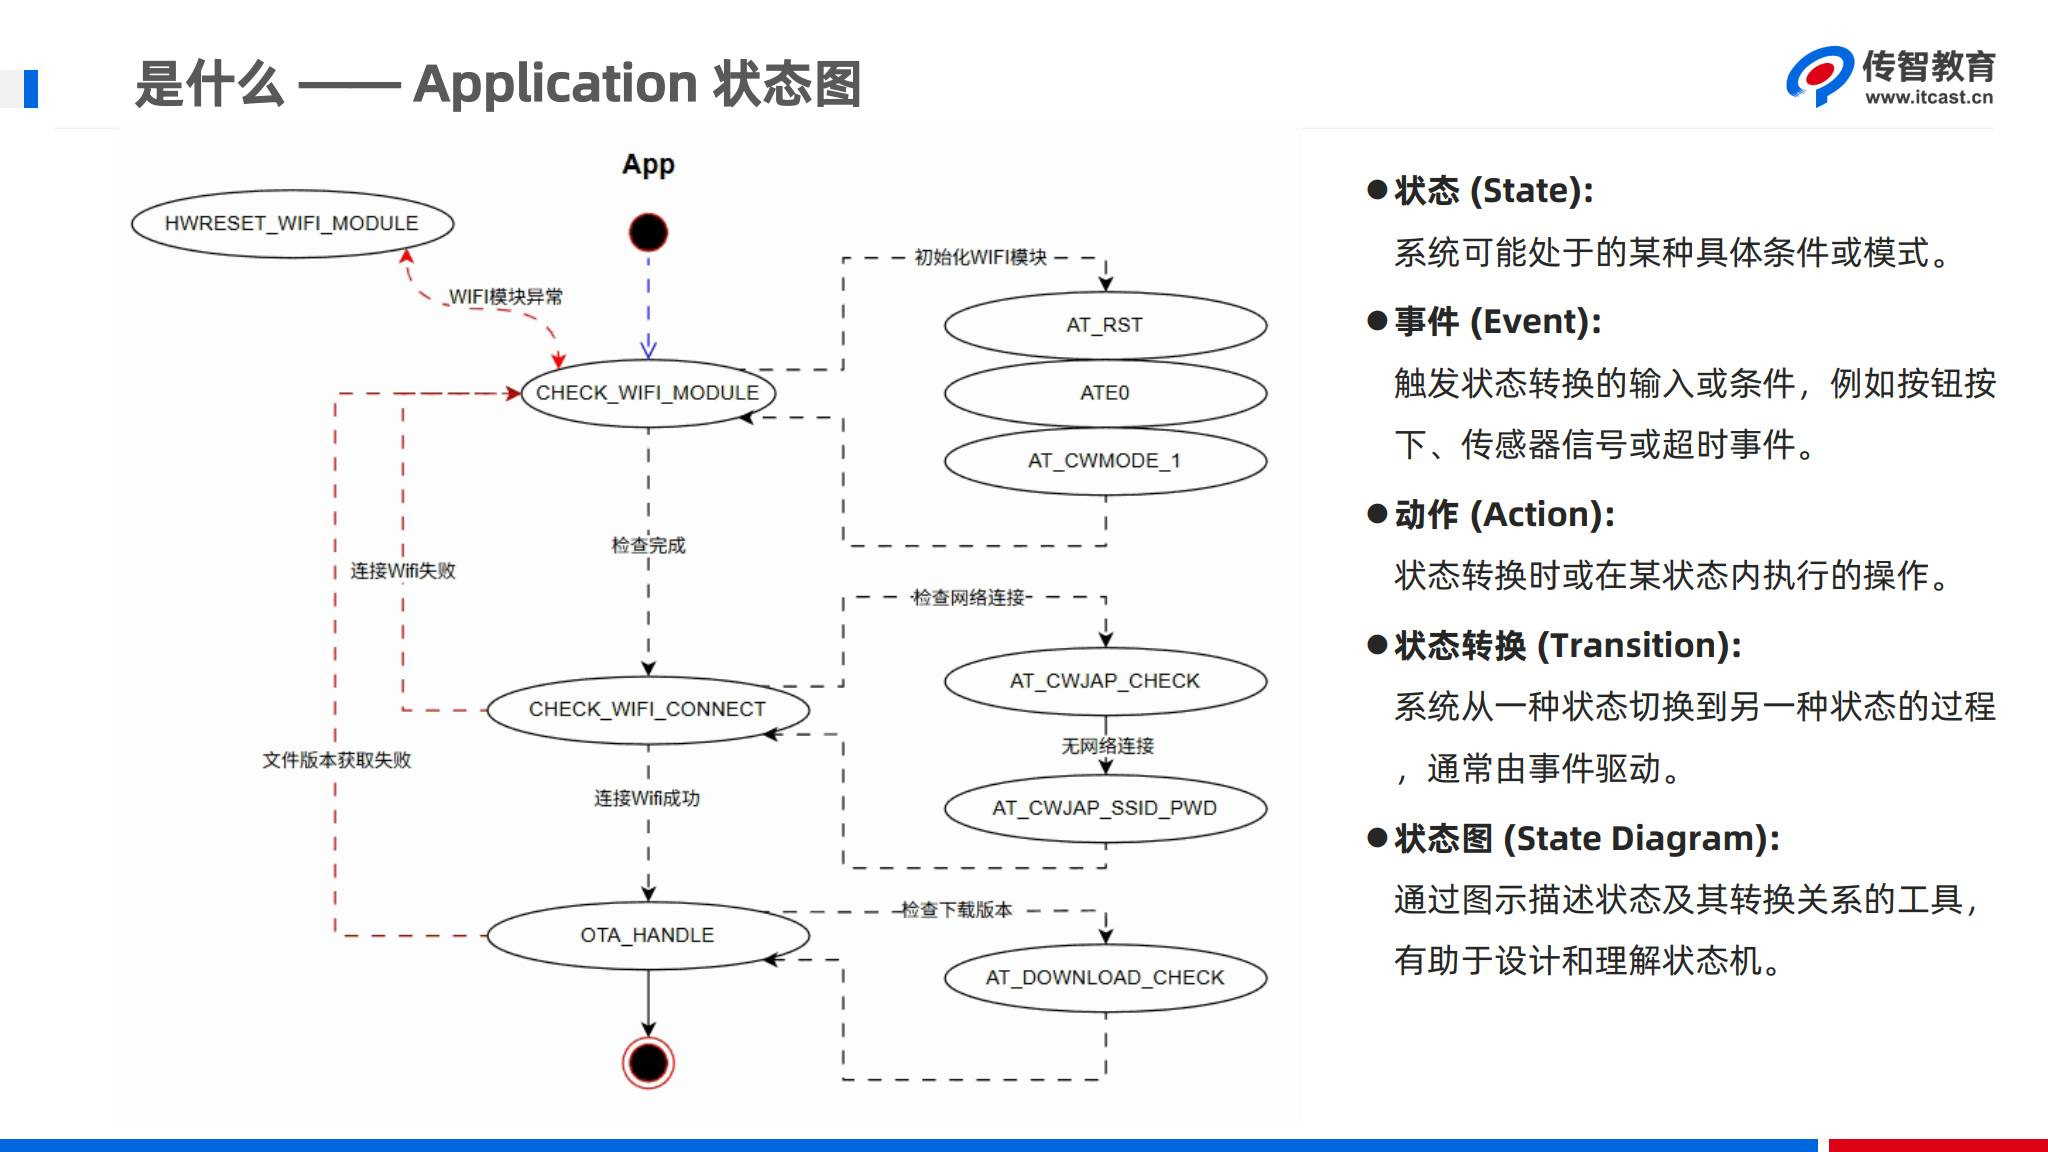

*讲义第72页，左侧是App主状态，右侧虚线框展开具体AT子步骤。图中部分命名与最终源码不同，以下以源码符号为准。*

| 主状态 | 子流程函数 | 内部主要状态 | 全部成功后 |
|---|---|---|---|
| `CHECK_WIFI_MODULE` | `CheckWifiModuleWork()` | `AT_RST → AT_E0 → AT_CWMODE_STA` | 进入连接检查 |
| `CHECK_WIFI_CONNECT` | `CheckWifiConnect()` | `AT_CWJAP_STATUS / AT_CWJAP_CONNECT` | 进入OTA信息请求 |
| `OTA_HANDLE` | `HandleOTA()` | `AT_DOWNLOAD_CHECK` | 进入DONE |
| `HWRESET_WIFI_MODULE` | `HwresetWifiModule()` | EN复位与计数 | 回模块检查 |

主状态回答“正在进行哪个业务阶段”，子状态回答“这个阶段的哪条AT操作正在执行”。共同的返回类型 `WifiCommState_t` 只有三种结果：

```c
typedef enum {
    WIFI_COMM_WAIT,
    WIFI_COMM_OK,
    WIFI_COMM_FAIL
} WifiCommState_t;
```

主任务正常每2 ms调用一次。WAIT时保持原状态并返回；OK才进入下一阶段；FAIL按主状态机回退。每次调用都进入同一个函数，并不等于每次都重发一条命令，发送去重由下层 `AtCmdHandle()` 的static状态负责。

图中的 `AT_CWMODE_1`、`AT_CWJAP_CHECK`、`AT_CWJAP_SSID_PWD` 对应源码 `AT_CWMODE_STA`、`AT_CWJAP_STATUS`、`AT_CWJAP_CONNECT`。看代码时以“发什么、等什么、何时转换”对齐，不必强求图上的每个标识逐字一致。


## 3. 工程和通信入口：日志口与AT口分开看

本篇主要阅读 `06_GD32F407_OTA_App`：

| 文件 | 作用 |
|---|---|
| `App/App_Wifi.c` | 三个子流程、JSON提取、升级入口 |
| `Common/wifi_drv.c` | 发AT、接收回调、等待与超时 |
| `Common/wifi_drv.h` | 三态枚举、接收缓冲与驱动声明 |
| `Library/USART/USART_config.h` | 真正生效的串口管脚、波特率、DMA开关 |
| `User/tasks.c` | Wi-Fi任务周期2 ms、任务挂起 |
| `App/App_OLED.c`、`App/App_Keys.c` | 显示与长按事件 |
| `Common/store_app.*` | 参数区、版本和升级标志 |
| `Common/iap_driver.c` | 复位到Bootloader |

硬件延续08：

```text
GD32 PB10 / USART2_TX → ESP32-C3 IO6 / AT RX
GD32 PB11 / USART2_RX ← ESP32-C3 IO7 / AT TX
GD32 PB12 → ESP EN
GD32 GND ↔ ESP GND
```

配套配置启用USART0和USART2，均为115200。USART0用于printf调试，USART2用于AT通信；USART2接收缓冲1024字节，RX DMA开启，配置为DMA0/CH1及其对应子外设选择。`wifi_drv.c` 内还有旧硬件描述字段，**实际USART库配置才是追踪初始化和接收路径的依据**。

`WifiUartInit()`、`WifiDmaInit()` 在该驱动文件中是空壳；真正串口配置由主程序 `USART_init()` 和Library/USART承担。复制Wi-Fi文件到新工程时，不能因调用过这两个空函数就认为串口和DMA已经就绪。

观察日志时也要分清：PC串口工具看到的可能是GD32打印的收发内容，不一定是PC直接接着ESP。视频37/38曾用另一个独立ESP串口进行手动命令对照，这只是方便调试，不是系统必须使用两个ESP。


## 4. AtCmdHandle：第一次发送，后续等待

配套驱动函数如下，保留原实现：

```c
WifiCommState_t AtCmdHandle(char *cmd, char *rsp, uint32_t timeoutMs)
{
    static WifiCommState_t s_commState = WIFI_COMM_OK;
    static uint64_t s_sendCmdTime;
    // 首次发送
    if (s_commState != WIFI_COMM_WAIT)
    {
        if (cmd != NULL)
        {
            SendWifiModuleStr(cmd);
        }
        // 记录发送时间
        s_sendCmdTime = systick_get_tick();
        // 状态切换为等待响应
        s_commState = WIFI_COMM_WAIT;
        return s_commState;
    }

    // waiting
    // 超时检测
    if ((systick_get_tick() - s_sendCmdTime) >= timeoutMs)
    {
        // 超时
        s_commState = WIFI_COMM_FAIL;
        return s_commState;
    }

    // 成功检测
    g_pktRcvdLen = RecvWifiModuleStr(g_recvStrBuf);
    // 检查是否包含期待的响应字符串
    if (g_pktRcvdLen > 0 && strstr(g_recvStrBuf, rsp) != NULL)
    {
        s_commState = WIFI_COMM_OK;
        return s_commState;
    }

    return s_commState;
}
```

执行过程：

1. 初始 `s_commState` 为OK，因此第一次调用进入发送分支。
2. 串口发送命令，记录 `systick_get_tick()`，切换到WAIT并返回。
3. 下次调用时仍是WAIT，跳过发送，先检查超时。
4. 未超时则尝试接收，在本次字符串里寻找期望响应。
5. 找到时返回OK；时间超过限制则返回FAIL。
6. 下次再调用，OK或FAIL都不等于WAIT，因而可以发送下一条或重发原命令。

```text
第1次调用：Send → 记时 → WAIT
第2...N次：不重发 → 查超时/接收 → WAIT
满足条件：返回OK，调用方切子状态
确认超时：返回FAIL，调用方决定重试或回退
```

该函数内部static变量是所有调用共享的，**同一时刻只支持一个在途AT命令**。不能让OLED、按键和Wi-Fi任务分别并发调用它发送不同命令，否则会共用等待状态和计时。课程把AT操作串行放在Wi-Fi任务中，符合这个约束。

原实现先判超时，再消费接收。若任务被其他耗时回调拖延，等回到这里时已过阈值，即使缓冲中已有数据，也会先返回FAIL。它是课堂简化的超时策略，并不保证精确到达时刻的响应不会被误判。


## 5. 接收回调到字符串：课堂驱动的边界

`USART2_on_recv(rx_buffer, rx_cnt)` 把接收缓冲指针、接收标志和长度交给Wi-Fi层；`RecvWifiModuleStr()` 发现标志后拷贝到 `g_recvStrBuf`，随后 `AtCmdHandle()` 用 `strstr()` 查找期望文本。

```text
USART/DMA收到数据
  → USART2_on_recv：登记指针、长度、接收标志
  → RecvWifiModuleStr：取一段接收数据
  → AtCmdHandle：查找ready / OK / WIFI GOT IP / +HTTPCLIENT:
  → 子状态机根据WAIT、OK、FAIL推进
```

本篇处理的是短AT文本和任务JSON；后续固件bin是另一种接收问题，不能照搬 `strlen/strstr` 把二进制当文本。

原接收代码需要注意：

| 原实现特点 | 对阅读和复现的影响 |
|---|---|
| `memcpy(buffer, ..., g_pktLen)` 没有目标容量参数 | 上层必须确认长度，不能只凭1024宏就认为任何输入都安全 |
| 未显式在拷贝末尾写 `'\0'` | 依赖缓冲先前状态；文本解析前应保证结尾 |
| 接收指针指向底层可复用缓冲 | 必须明确DMA/中断与主循环的所有权和复用时机 |
| 单个接收标志和长度 | 连续多段响应可能被覆盖，未体现消息队列 |
| `strstr` 搜索当前接收块 | 期望文本跨两个块到达时可能找不到 |
| 发送/接收会printf整行 | 生产日志可能泄漏Authorization或Wi-Fi口令 |

一个AT响应可能分多段到达，`+HTTPCLIENT:` 前缀出现也不表示整段JSON已到齐。后续完善应按响应格式累积、检查长度、再提交解析。本篇保留课堂结构，不能据此声称已有完整的串口流解析器。

文本缓冲的一般约束是 `接收长度 < 缓冲容量`，给终止符预留一个字节。长度等于1024时，不能再往1024字节数组的 `buffer[1024]` 写终止符。


## 6. 模块检查的三条命令与成功判据

视频37先用串口工具观察命令响应，再把规则放进状态机：

| 子状态 | 命令 | 期望响应 | 源码超时 |
|---|---|---|---:|
| `AT_RST` | `AT+RST\r\n` | `ready\r\n` | 3000 ms |
| `AT_E0` | `ATE0\r\n` | `OK\r\n` | 1000 ms |
| `AT_CWMODE_STA` | `AT+CWMODE=1\r\n` | `OK\r\n` | 1000 ms |

**软复位应等待ready。** AT+RST之后很快出现的OK可理解为命令被接收，模块真正重启就绪还要等待ready；若收到OK就立刻发送下一条，可能撞上启动过程。

ATE0关闭命令回显，避免接收内容再混入原始命令。它不会关闭真正的应答，也不表示串口静默。CWMODE=1把ESP设为Station，使它作为客户端连接路由器/AP。

超时时间看函数实参，源码中ATE0/CWMODE旁的部分注释仍写“3000ms”，实际传入是1000；不能把旧注释当成运行参数。

子状态定义：

```c
typedef enum {
    AT_RST = 0,
    AT_E0,
    AT_CWMODE_STA
} AtCheckModuleCmdType;
```

顺序是重置、关回显、设模式。最后一条成功后，把子状态恢复AT_RST，为将来再次进入这套流程准备，同时向主任务返回OK。


## 7. CheckWifiModuleWork完整代码与RETRY含义

配套子流程：

```c
WifiCommState_t CheckWifiModuleWork(void){
//    printf("1. Check Wifi Module Work\r\n");
    static AtCheckModuleCmdType cmdType = AT_RST;
    static uint8_t retryCount = 0;
    WifiCommState_t commState = WIFI_COMM_WAIT; 

    switch (cmdType) {
        case AT_RST:
            // 发起AT指令, 并等待指定应答ready\r\n, 超时时间3000ms
            commState = AtCmdHandle("AT+RST\r\n", "ready\r\n", 3000);
            if(commState == WIFI_COMM_OK){
                cmdType = AT_E0; // 状态切换(流转)
            }else if(commState == WIFI_COMM_FAIL){
                RETRY(AT_RST); // 重试3次, 再返回失败
            }
            break;
        case AT_E0:
            // 发起AT指令, 并等待指定应答OK\r\n, 超时时间3000ms
            commState = AtCmdHandle("ATE0\r\n", "OK\r\n", 1000);
            if(commState == WIFI_COMM_OK){
                cmdType = AT_CWMODE_STA; // 状态切换(流转)
            }else if(commState == WIFI_COMM_FAIL){
                RETRY(AT_RST); // 重试3次, 再返回失败
            }
            break;
        case AT_CWMODE_STA:
            // 发起AT指令, 并等待指定应答OK\r\n, 超时时间3000ms
            commState = AtCmdHandle("AT+CWMODE=1\r\n", "OK\r\n", 1000);
            if(commState == WIFI_COMM_OK){
                cmdType = AT_RST; // 状态切换(流转)
                // 返回成功
                return WIFI_COMM_OK;
            }else if(commState == WIFI_COMM_FAIL){
                RETRY(AT_RST); // 重试3次, 再返回失败
            }
            break;
    }

    return WIFI_COMM_WAIT;
}
```

配套重试宏：

```c
#define RETRY(fallback_cmdType)            \
    do {                                   \
        if (++retryCount >= 3) {           \
            cmdType = fallback_cmdType;    \
            retryCount = 0;                \
            return WIFI_COMM_FAIL;         \
        }                                  \
    } while (0)
```

这个宏依赖调用函数里存在 `static retryCount` 和 `cmdType`，其中 `return` 会直接返回**当前子流程函数**。`do { ... } while (0)` 让多条语句在语法上像一条语句，不是让程序一直循环执行。

按源码严格解释：

- 第1、2次失败：只增加计数，宏不返回；子状态保持原值，函数最终返回WAIT，下次再次发送。
- 第3次失败：重置子状态到传入回退值，计数清零，向主状态机返回FAIL。
- 所以它是在第3次失败后退出，**不是第一次失败后额外再给三次、合计四次尝试**。
- 三条命令共用本函数同一个计数；正常成功分支没有清零retryCount。因此该实现累计的是此函数残留的失败次数，不能严格称为“每条命令连续失败三次”。

例如RST失败两次后成功，ATE0只要再失败一次，累加到3就会返回FAIL。即便整套流程成功，retryCount也可能保留到将来再次进入。若期望“每条命令成功即清零”或“每轮流程独立计数”，需明确在哪里重置，这是补充改进，并非原码已有行为。

主状态机收到本函数FAIL才进入硬件复位分支。硬复位恢复次数上限与这里的AT失败计数是两套计数，不能混作“所有故障总共只尝试三次”。


## 8. 模块检查的课程验证与预期日志

视频37完成后观察到如下次序：

```text
发送AT+RST
  → 等待ESP重启
  → 收到ready
发送ATE0
  → 收到OK
发送AT+CWMODE=1
  → 收到OK
  → 主状态流转到CHECK_WIFI_CONNECT
```

这说明课堂硬件中模块基础通信和三条配置命令可用，**尚未说明已经取得IP或访问OneNET成功**。

复现时可按以下情况检查：

| 现象 | 优先检查 |
|---|---|
| 不断AT+RST，始终等不到ready | 接线、AT口、固件、波特率、EN状态、接收是否丢段 |
| 收到OK却仍未继续 | RST期望的是ready，不能只按OK判断 |
| 重启后回显又出现 | 重置可能恢复回显，需重新ATE0 |
| ATE0/CWMODE超时很快 | 看实际1000 ms参数，检查调度阻塞和串口接收 |
| 两次RST失败后ATE0一败就上抛 | 同函数retryCount跨命令累计，符合原宏行为 |
| 任务已进入连接检查 | 模块阶段完成，接下来排查网络层 |

课堂测试完成后关闭过密的“第1阶段”日志，保留发送、结果和异常线索即可。2 ms周期下每次WAIT都打印，会让日志和串口时序本身成为干扰。


## 9. Wi-Fi连接：先查已有连接，再决定是否加入热点

视频38先手工发送：

```text
AT+CWJAP?
```

已连AP时返回包含 `+CWJAP:` 的AP信息；课堂未连接时没有这段AP信息。因此源码不把查询最后的OK当成“已连接”，而是等待 `+CWJAP:`：

```c
AtCmdHandle("AT+CWJAP?\r\n", "+CWJAP:", 1000);
```

如果收到该信息，当前子流程直接返回OK；如果1秒内找不到，转入连接子状态。这个FAIL在此处表示“查询没有满足期望”，不是马上向主状态机报告网络彻底失败。

连接命令和参数结构：

```c
typedef struct {
    char *cmd;
    char *rsp;
    uint32_t timeoutMs;
} AtCmdInfo_t;

/* 示例占位值，不含课程真实口令 */
char g_apSSID[32] = "YOUR_SSID";
char g_apPwd[32] = "YOUR_PASSWORD";

const static AtCmdInfo_t g_connectApCmdInfo = {
    .cmd = "AT+CWJAP=\"%s\",\"%s\"\r\n",
    .rsp = "WIFI GOT IP\r\n",
    .timeoutMs = 8000
};
```

`sprintf` 把SSID/密码代入两个%s，形成完整命令；相较把命令、响应、超时散写在case里，结构体把同一操作的配置放到一起。接口很相似时仍应核对真实命令，不能把ssid/pwd当成HTTP用户名密码。

本例32字节数组含字符串结尾，只能容纳最多31字节的内容，不代表已经覆盖所有合法Wi-Fi配置。实际移植要按需要扩展、检查容量，并处理AT参数中逗号、引号和反斜线等字符的转义。


## 10. CheckWifiConnect完整实现与IP就绪边界

配套函数如下：

```c
WifiCommState_t CheckWifiConnect(void){
    // printf("2. Check Wifi Connect\r\n");
    static AtCheckConnectCmdType cmdType = AT_CWJAP_STATUS;
    static uint8_t retryCount = 0;
    WifiCommState_t commState = WIFI_COMM_WAIT;
    char cmdStrBuf[128];

    switch (cmdType) {
        case AT_CWJAP_STATUS:
            commState = AtCmdHandle("AT+CWJAP?\r\n", "+CWJAP:", 1000);
            if(commState == WIFI_COMM_OK){
                return WIFI_COMM_OK;
            }else if(commState == WIFI_COMM_FAIL){
                cmdType = AT_CWJAP_CONNECT; // 状态切换(流转)
            }
            break;
        case AT_CWJAP_CONNECT:
            sprintf(cmdStrBuf, g_connectApCmdInfo.cmd, g_apSSID, g_apPwd);
            commState = AtCmdHandle(cmdStrBuf, g_connectApCmdInfo.rsp, g_connectApCmdInfo.timeoutMs);
            if(commState == WIFI_COMM_OK){
                cmdType = AT_CWJAP_STATUS; // 状态切换(流转)
                return WIFI_COMM_OK;
            }else if(commState == WIFI_COMM_FAIL){
                RETRY(AT_CWJAP_STATUS);
            }
            break;
        default:
            break;
    }
    
    return WIFI_COMM_WAIT;
}
```

状态转换：

```text
AT_CWJAP_STATUS
  ├─ 收到+CWJAP: → 直接OK
  ├─ WAIT → 原状态
  └─ 超时FAIL → AT_CWJAP_CONNECT

AT_CWJAP_CONNECT
  ├─ 收到WIFI GOT IP → 子状态复位为STATUS，返回OK
  ├─ WAIT → 原状态
  └─ FAIL → RETRY；第3次失败后回STATUS并返回FAIL
```

**视频和源码的差异：** 视频38讨论过先用OK、再用取得IP消息，后面为演示流转又临时尝试WIFI CONNECTED；最终配套结构体写的是 `WIFI GOT IP\r\n`。笔记保留最终代码，并按官方含义区分：

| 信息 | 说明 |
|---|---|
| `WIFI CONNECTED` | Wi-Fi关联成功 |
| `WIFI GOT IP` | 已获得IP地址 |
| 能访问OneNET | 还需要路由、DNS、网络服务和鉴权正常 |

“连上AP”并不自动证明DHCP完成，更不能证明互联网可达。查询 `+CWJAP:` 也主要提供AP信息，不能代替完整IP可用性检查；需要更稳妥时，应结合状态/IP查询或实际HTTP结果确认。

视频40观察到刚联网后的第一次HTTP出现busy，第二次才成功。它是课堂当时的现象，不是“所有ESP第一次请求必然失败”的协议规则。排查时关注IP就绪、上一条AT是否真正结束，以及驱动是否只看到中间事件就发了下一条。


## 11. OneNET check配置与命令缓冲容量

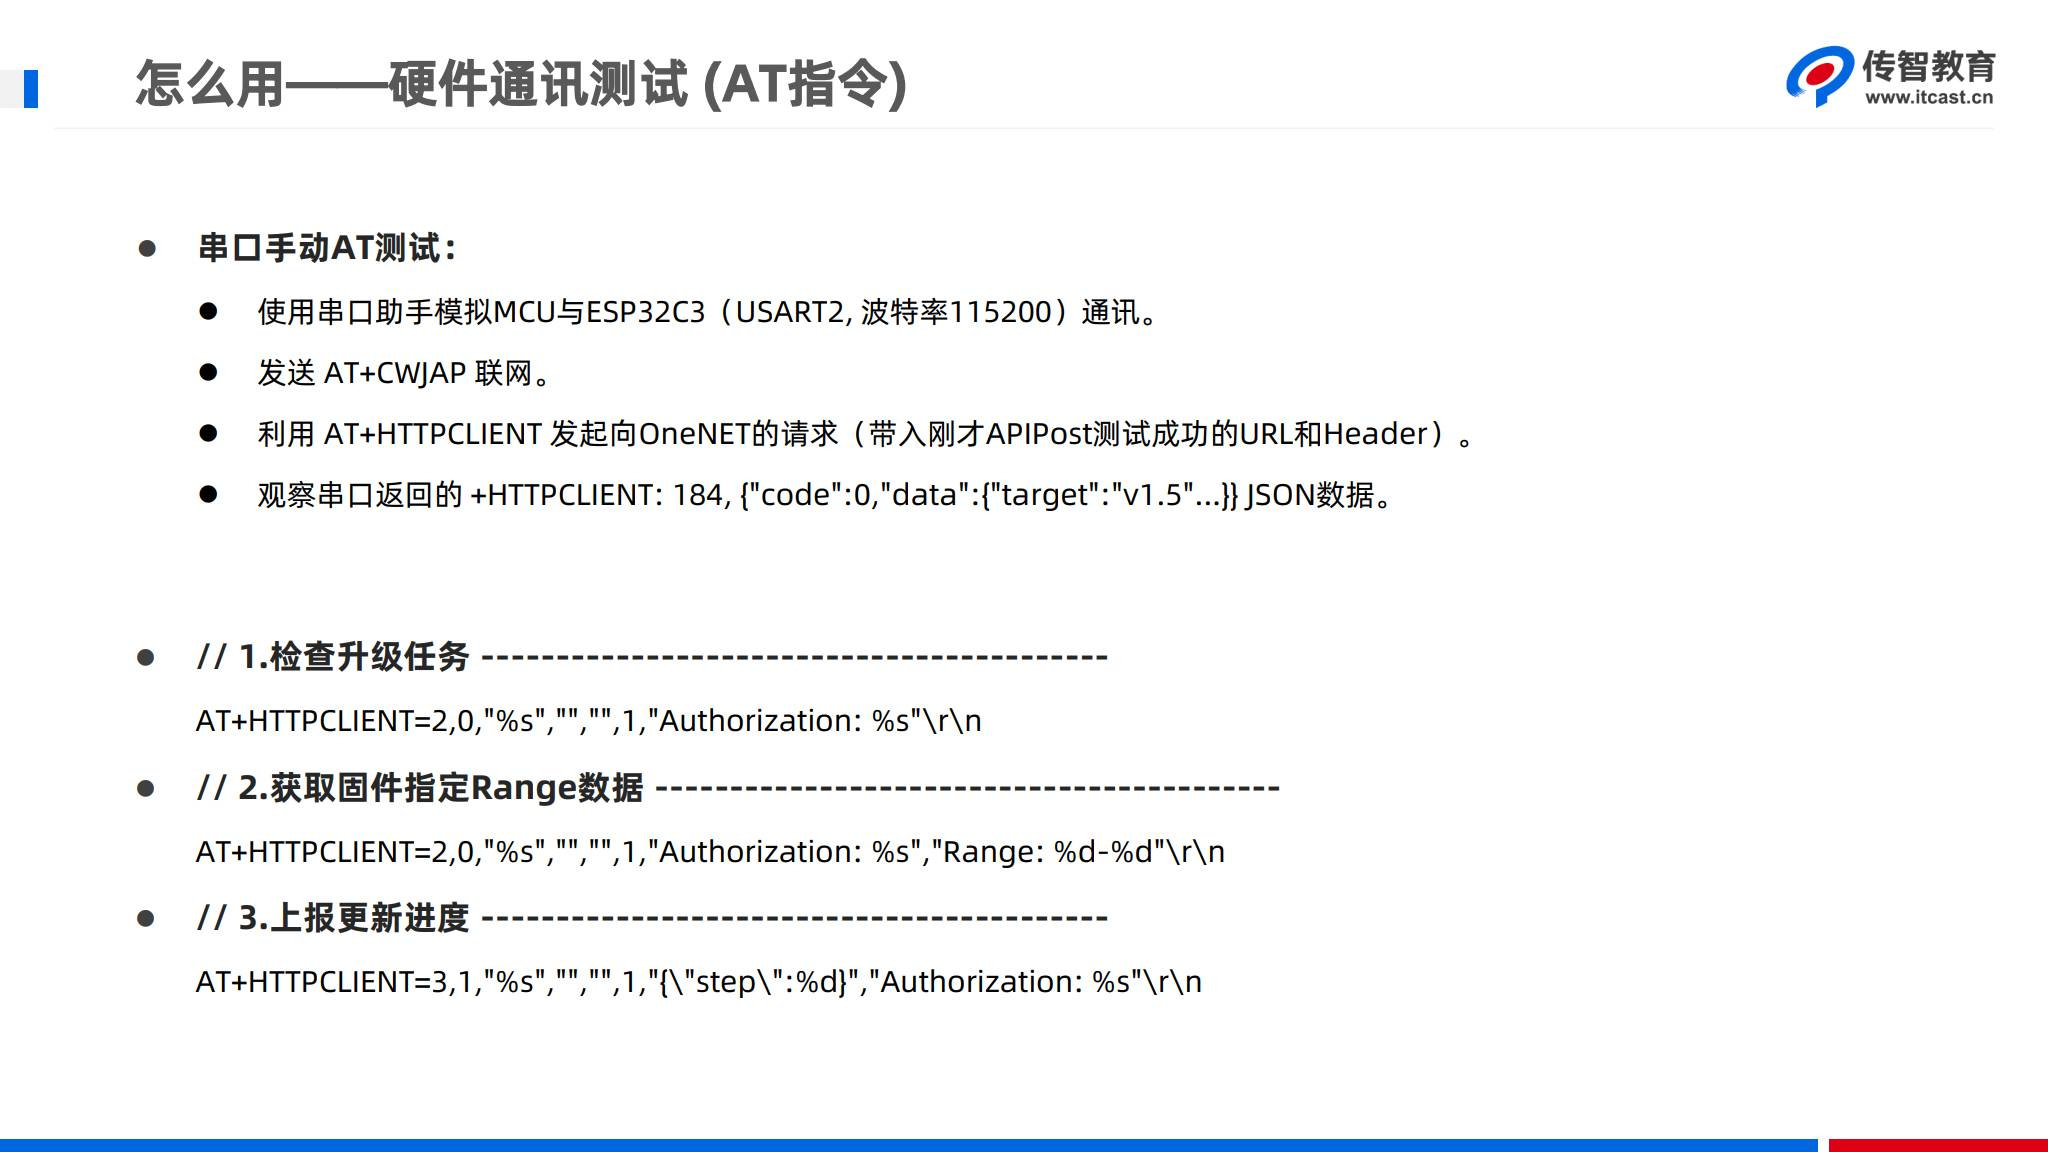

*讲义第69页，本文使用第一条“检查升级任务”；下载和状态上报仅用于衔接后续。*

配套源码把产品、设备、URL和Authorization组合成一次GET请求。以下用占位值重写配置：

```c
#define PROD_ID   "YOUR_PRODUCT_ID"
#define DEVICE_ID "YOUR_DEVICE_NAME"

const char *g_otaCheckUrl =
    "http://iot-api.heclouds.com/fuse-ota/"
    PROD_ID "/" DEVICE_ID "/check?type=1&version=1.0";

const char *g_otaAuthHeader = "YOUR_COMPLETE_TOKEN";

const AtCmdInfo_t g_downloadCheckCmdInfo = {
    .cmd = "AT+HTTPCLIENT=2,0,\"%s\",\"\",\"\",1,"
           "\"Authorization: %s\"\r\n",
    .rsp = "+HTTPCLIENT:",
    .timeoutMs = 8000
};
```

编译器会把相邻字符串字面量连接起来，所以宏可以夹在URL字符串中。Authorization值已经包含Token各参数，不能再把设备key原样当作Token，也不要重复URL编码。

`type=1` 在check查询中表示FOTA；`version` 是设备当前固件版本。**原包固定写死 `version=1.0`，而参数宏使用 `APP_VERION "v1.0"`。** 它没有自动从当前参数版本构造URL；复现应统一字符串规范，后续升级后也要带真实当前版本。固定旧版本会影响任务匹配和重复检测。

原 `HandleOTA()` 的命令缓冲为256字节。本次对配套固定字符串做静态长度核算，完整指令235字节，含终止符需236，能放入该缓冲；这只适用于那组短产品/设备名及Token。替换成长设备资源Token或更长版本后，应重新核算。

补充改进：

```c
int n = snprintf(cmdStrBuf, sizeof(cmdStrBuf),
                 g_downloadCheckCmdInfo.cmd,
                 g_otaCheckUrl, g_otaAuthHeader);
if (n < 0 || (size_t)n >= sizeof(cmdStrBuf)) {
    return WIFI_COMM_FAIL;
}
```

不要在Token较长时继续使用未检查的sprintf。课堂使用http和transport_type=1；若改HTTPS，需与transport_type及TLS配置一起核对，不能只换URL前缀。


## 12. HandleOTA：AT匹配成功与业务成功是不同层次

配套代码：

```c
WifiCommState_t HandleOTA(void){
//    printf("3. Handle OTA\r\n");
    static AtDownloadCmdType cmdType = AT_DOWNLOAD_CHECK;
    static uint8_t retryCount = 0;
    WifiCommState_t commState = WIFI_COMM_WAIT;
    char cmdStrBuf[256];
    switch (cmdType) {
        case AT_DOWNLOAD_CHECK:
            sprintf(cmdStrBuf, g_downloadCheckCmdInfo.cmd, g_otaCheckUrl, g_otaAuthHeader);
            commState = AtCmdHandle(cmdStrBuf, g_downloadCheckCmdInfo.rsp, g_downloadCheckCmdInfo.timeoutMs);
            if(commState == WIFI_COMM_OK){

//                printf("OTA[%d]->%s\r\n", g_pktRcvdLen, g_recvStrBuf);
                parse_json_data(g_recvStrBuf);

                return WIFI_COMM_OK;
            }else if(commState == WIFI_COMM_FAIL){
                RETRY(AT_DOWNLOAD_CHECK);
            }
            break;
        default:
            break;
    }
    
    return WIFI_COMM_WAIT;
}
```

主要步骤：格式化HTTPCLIENT命令，调用AT驱动，等到 `+HTTPCLIENT:` 后，把 `g_recvStrBuf` 交给 `parse_json_data()`，然后向主状态机返回OK。超时则按同一RETRY宏重发，第3次累计失败后向上返回FAIL。

需要明确两点：

1. `+HTTPCLIENT:` 是AT输出前缀，**不保证整个JSON已收齐，也不等于JSON code=0**。
2. 原函数调用了 `parse_json_data(g_recvStrBuf)`，但**没有检查它的返回值**。即便解析返回-1，仍可能返回WIFI_COMM_OK并进入DONE。

理解返回层次：

```text
串口收到了目标前缀
    ≠ HTTP请求业务成功
    ≠ 收到了完整且合法的JSON
    ≠ 四个字段都有效
    ≠ 目标版本可升级
    ≠ 固件已经升级完成
```

改进时应先在接收层获得完整正文，再解析并分类结果：有效任务、明确无任务、临时网络/鉴权错误、格式错误。不能把所有非零业务code都写成“没有新版本”，也不能把明确无任务当成每2 ms都要重试的故障。

下面的片段仅说明**解析失败应向上传递**，不能替代完整接收与业务分类：

```c
if (commState == WIFI_COMM_OK) {
    if (parse_json_data(g_recvStrBuf) != 0) {
        return WIFI_COMM_FAIL;
    }
    return WIFI_COMM_OK;
}
```

若这样改后上层不断重连，应继续区分无任务与真实错误，并设计重试间隔；不要为使流程看起来“成功”又忽略解析结果。


## 13. cJSON接入：Pack版本与工程组件核对

视频40使用配套 `MDK-Packs.cJSON.1.0.0.pack`，安装后在Keil运行环境组件管理中勾选：

```text
Data Exchange → JSON → cJSON
```

然后在业务文件包含：

```c
#include "cJSON.h"
```

配套 `Project/GD32F407.uvprojx` 记录：

| 项目 | 值 |
|---|---|
| Pack供应方 | MDK-Packs |
| Pack名称/版本 | cJSON / 1.0.0 |
| 组件分类 | Data Exchange / JSON / cJSON |
| cJSON组件版本 | 1.7.7 |

**Pack 1.0.0不等于cJSON库版本1.0.0。** 不要只看文件名数字就推断API版本。压缩包工程依赖Pack组件，没有在本App目录里直接附一份cJSON.c/h；复现时若找不到头文件或链接不到函数，要核对组件安装、勾选、包含路径和工程使用的工具链。

另一种接入方法是直接添加cJSON.c/h，但如果已经通过Pack引入，不要再把同名实现重复编译。课堂采用Pack方式，本次只检查工程配置，没有安装软件或修改现有工程。

cJSON解析会为对象树及字符串分配内存，默认使用malloc/free；裸机工程除了头文件可见，还要有可用的堆配置，分配失败时 `cJSON_Parse()` 会返回NULL。下文解释清理时会用到 `cJSON_Delete()`。


## 14. 从HTTPCLIENT包络取出JSON正文

任务返回不是一开始就是 `{`，串口里还带AT前缀和结束信息：

```text
+HTTPCLIENT:<长度>,{"code":0,...}\r\nOK\r\n
```

视频40把过程称为“掐头去尾”：

1. 用 `strchr(jsonStr, '{')` 找到JSON起点。
2. 若尾部恰好是 `"\r\nOK\r\n"`，把它去掉。
3. 再将JSON字符串交给cJSON解析。

尾部字符串共有6字节：CR、LF、O、K、CR、LF，因此原码用 `strlen(pJson)-6` 取最后六个字符。

补充说明：执行减6之前，必须确认输入非NULL、是有效终止字符串，且长度至少6。否则短响应可能发生无符号下溢和越界。示意：

```c
/* 前提：jsonStr已按接收长度限定，且保证'\0'结尾 */
if (jsonStr == NULL) return -1;
char *pJson = strchr(jsonStr, '{');
if (pJson == NULL) return -1;

size_t len = strlen(pJson);
if (len >= 6 && memcmp(pJson + len - 6, "\r\nOK\r\n", 6) == 0) {
    pJson[len - 6] = '\0';
}
```

这只是修补课堂尾部判断的边界。真实AT接收应根据 `+HTTPCLIENT:<长度>,` 的长度界定payload并累积完整片段；不能一找到第一个大括号，就假定后面一定是唯一、完整的任务JSON。

cJSON 1.7.7文档说明，普通 `cJSON_Parse()` 默认不会把JSON后面的其他字符都当错误。也就是说，课堂去尾有助于整理输入，但不能反过来声称“末尾有OK就绝不可能解析成功”。需要严格限制单一JSON时，可在已分离的正文上使用带结束检查的解析接口。


## 15. 四个目标字段：先定位data，再读取类型和值

视频40关注 `target`、`tid`、`size`、`md5`。下面为独立构造的示例，MD5占位值不对应任何课程固件：

```json
{
  "code": 0,
  "msg": "succ",
  "data": {
    "target": "v1.6",
    "tid": 123,
    "size": 32656,
    "md5": "0123456789abcdef0123456789abcdef",
    "status": 1,
    "type": 1
  },
  "request_id": "example-request"
}
```

| JSON字段 | cJSON类型/成员 | 课程保存位置 | 作用 |
|---|---|---|---|
| `code` | Number，`valueint` | 局部检查 | 0为接口业务成功 |
| `msg` | String，`valuestring` | 日志 | 说明业务结果 |
| `data` | Object | 局部指针 | 外层到具体任务的桥梁 |
| `target` | String | `g_otaVerNo[32]` | 新版本显示 |
| `tid` | Number | `static uint32_t g_otaTaskId` | 下载/上报任务路径 |
| `size` | Number | `uint32_t g_otaBinSize` | 显示与容量、下载长度 |
| `md5` | String | `static char *g_targetMD5` | 后续整包校验依据 |

读取示例：

```c
cJSON *root = cJSON_Parse(pJson);
if (root == NULL) return -1;

cJSON *data = cJSON_GetObjectItem(root, "data");
cJSON *target = cJSON_GetObjectItem(data, "target");
if (cJSON_IsString(target)) {
    printf("target: %s\r\n", target->valuestring);
}
```

这段只是API用法示意，最终所有退出路径都还需要释放root。`cJSON_IsString/IsNumber/IsObject` 用来判断类型；不要直接解引用一个可能不存在的字段。

数字还要检查业务范围：大小应大于0且不超过App容量，任务ID应在设备支持的整数范围内；不能先把负size转成uint32_t，再拿它当很大的合法包。源码用valueint适合课堂短数值，通用任务ID要注意其有符号int范围。

完整包/差分包类型也应检查。本课没有差分重建逻辑，`data.type=2` 时不能把下载内容直接当完整App安装。课程这一阶段主要演示四字段提取，未实现所有这些业务验证。


## 16. parse_json_data配套原码与逐段理解

下面保留配套App的函数，便于对照课堂，**其中已知边界在后两节说明，不应作为已完善的解析器直接用于产品**：

```c
int8_t parse_json_data(char* jsonStr){
    // 1. 寻找JSON开始位置 '{'
    char *pJson = strchr(jsonStr, '{');
    if(pJson == NULL){
        printf("JSON解析错误: 未找到JSON开始位置 '{'\r\n");
        return -1;
    }

    // 如果结尾是\r\nOK\r\n去掉
    if(strncmp(pJson + strlen(pJson) - 6, "\r\nOK\r\n", 6) == 0){
        pJson[strlen(pJson) - 6] = '\0';
    }

    // 2. 解析JSON字符串
    cJSON *root = cJSON_Parse(pJson);
    if(root == NULL){
        printf("JSON解析错误: 未找到JSON字符串\r\n");
        return -1;
    }

    // 3. 提取code, data
    cJSON *code = cJSON_GetObjectItem(root, "code");
    cJSON *msg = cJSON_GetObjectItem(root, "msg");
    if(cJSON_IsNumber(code) && cJSON_IsString(msg)){
        printf("code: %d, msg: %s\r\n", code->valueint, msg->valuestring);
        
        if(code->valueint != 0){
            printf("无升级包, 不需要升级\r\n");
            return -1;
        }
    }

    // 4. 通过data提取target, tid, size, md5
    cJSON *data = cJSON_GetObjectItem(root, "data");
    if(!cJSON_IsObject(data)){
        printf("JSON解析错误: 未找到data对象\r\n");
        return -1;
    }
    cJSON *target = cJSON_GetObjectItem(data, "target");
    cJSON *tid = cJSON_GetObjectItem(data, "tid");
    cJSON *size = cJSON_GetObjectItem(data, "size");
    cJSON *md5 = cJSON_GetObjectItem(data, "md5");
    
    // 打印提取的结果
    if (cJSON_IsString(target)) printf("固件名称: %s\r\n", target->valuestring);
    if (cJSON_IsNumber(size)) printf("固件大小: %d\r\n", size->valueint);
    if (cJSON_IsNumber(tid)) printf("任务id: %d\r\n", tid->valueint);
    if (cJSON_IsString(md5)) printf("校验和: %s\r\n", md5->valuestring);

    // 赋值给全局变量
    strcpy(g_otaVerNo, target->valuestring);
    // 固件大小
    g_otaBinSize = size->valueint;
    // 任务id
    g_otaTaskId = tid->valueint;
    // MD5校验和
    g_targetMD5 = md5->valuestring;

    return 0;
}
```

阅读顺序：

1. 找 `{`，找不到则打印并返回-1。
2. 检查尾部AT结束串，写 `'\0'` 截断。
3. 调用cJSON_Parse，失败则返回-1。
4. 取code/msg，条件满足时打印；若code非0则返回-1。
5. 取data对象，再取四个字段。
6. 根据类型分别打印。
7. 将值保存到全局变量，返回0。

数组和指针的区别是视频40的重点：

```c
strcpy(g_otaVerNo, target->valuestring);  /* 数组：复制字符 */
g_otaBinSize = size->valueint;           /* 数值：复制数值 */
g_otaTaskId = tid->valueint;
g_targetMD5 = md5->valuestring;          /* 指针：只复制地址 */
```

C数组不能通过 `g_otaVerNo = target->valuestring` 变成另一串字符；指针赋值则不会自动复制MD5文本。后者会引出所有权和生命周期问题，不能理解成“指针只能这样保存，已经安全持有字符串”。

视频里完成函数后曾忘记从HandleOTA调用，随后补上才看到OLED显示真实版本。**实现了函数但没接到主流程，不会自动生效。** 复现时要同时核对“函数内容”和“调用位置”。


## 17. 字段验证与内存生命周期：原实现需要补上的部分

按源码核对：

| 原实现位置 | 实际行为 | 改进方向 |
|---|---|---|
| code/msg类型判断包裹了code检查 | 类型异常时可能跳过code验证继续往下 | 必须字段缺失/类型错误直接失败 |
| 四个字段只在打印时判类型 | 随后的复制/赋值仍无条件执行 | 验证全部字段后再使用 |
| `strcpy(g_otaVerNo, ...)` | 不检查源字符串长度 | 根据最小消费端容量限定长度 |
| `strlen(pJson)-6` | 未检查长度下限 | 输入长度与终止符先确认 |
| root解析成功后没有Delete | 正常与错误退出会泄漏解析树 | 所有路径统一清理 |
| `g_targetMD5 = md5->valuestring` | 保存解析树内部字符串地址 | 清理前复制到自有缓冲 |
| 非零code打印“无升级包” | 网络/鉴权等业务错误可能也归到无包 | 按返回码分类记录 |
| HandleOTA忽略解析返回值 | 主任务仍可能进入DONE | 解析结果与主状态对接 |

**不能只在末尾补一句cJSON_Delete(root)。** 原来g_targetMD5还指向树里的字符串，树释放后会成为悬空指针。正确顺序是：验证 → 复制所需数据到自己拥有的存储 → 释放root → 提交新元数据。

`g_otaVerNo` 全局虽有32字节，但OLED和升级入口使用16字节版本缓冲，参数区 `softwareVersion` 也为16字节。若延续这些接口，目标版本上限应统一到15字节加终止符，或者整体扩容并迁移参数格式，不能只扩大一个数组。

本App常在一次成功查询后挂起Wi-Fi任务，可能暂时掩盖重复解析造成的泄漏；这不等于泄漏不存在。后续添加定期查询、重试或恢复任务时，问题更容易暴露。


## 18. 补充改进：解析到自有快照，再一次性提交

下面是独立的学习用改进片段，输入为**已经完整分离、以NUL结尾的单段JSON正文**。它不替代AT接收层，也不自动接入课程工程；需要按工程接口适配。未进行目标编译或硬件测试。

```c
#include <stdbool.h>
#include <stdint.h>
#include <string.h>
#include "cJSON.h"
#include "store_app.h"

typedef struct {
    char target[16];
    uint32_t tid;
    uint32_t size;
    char md5[33];
} OtaTaskInfo;

/* 排除负数、小数、NaN、无穷大和uint32_t范围外的数 */
static bool PositiveU32(const cJSON *item, uint32_t *out) {
    double v;
    uint32_t n;
    if (!cJSON_IsNumber(item) || out == NULL) return false;
    v = item->valuedouble;
    if (!(v >= 1.0 && v <= 4294967295.0)) return false;
    n = (uint32_t)v;       /* 先确认范围，再转换 */
    if ((double)n != v) return false;
    *out = n;
    return true;
}

static bool IsMd5Hex(const char *s) {
    size_t i;
    if (s == NULL || strlen(s) != 32) return false;
    for (i = 0; i < 32; ++i) {
        char c = s[i];
        if (!((c >= '0' && c <= '9') ||
              (c >= 'a' && c <= 'f') ||
              (c >= 'A' && c <= 'F'))) return false;
    }
    return true;
}

static bool ParseTaskJson(const char *json, OtaTaskInfo *out) {
    bool ok = false;
    OtaTaskInfo tmp = {0};
    cJSON *root = NULL;
    cJSON *code, *data, *target, *tid, *size, *md5, *type;

    if (json == NULL || out == NULL) return false;
    root = cJSON_ParseWithOpts(json, NULL, 1);
    if (root == NULL) return false;

    code = cJSON_GetObjectItemCaseSensitive(root, "code");
    data = cJSON_GetObjectItemCaseSensitive(root, "data");
    if (!cJSON_IsNumber(code) || code->valuedouble != 0 ||
        !cJSON_IsObject(data)) goto done;

    target = cJSON_GetObjectItemCaseSensitive(data, "target");
    tid = cJSON_GetObjectItemCaseSensitive(data, "tid");
    size = cJSON_GetObjectItemCaseSensitive(data, "size");
    md5 = cJSON_GetObjectItemCaseSensitive(data, "md5");
    type = cJSON_GetObjectItemCaseSensitive(data, "type");

    if (!cJSON_IsString(target) || target->valuestring == NULL ||
        !cJSON_IsString(md5) || md5->valuestring == NULL ||
        !cJSON_IsNumber(type) || type->valuedouble != 1) goto done;
    if (target->valuestring[0] == '\0' ||
        strlen(target->valuestring) >= sizeof(tmp.target)) goto done;
    if (!PositiveU32(tid, &tmp.tid) ||
        !PositiveU32(size, &tmp.size) || tmp.size > APP_SIZE) goto done;
    if (!IsMd5Hex(md5->valuestring)) goto done;

    strcpy(tmp.target, target->valuestring);
    strcpy(tmp.md5, md5->valuestring);
    *out = tmp;           /* 验证全通过后才提交 */
    ok = true;

done:
    cJSON_Delete(root);
    return ok;
}
```

这里的MD5数组33字节存32个十六进制字符加结尾0；target16字节与现有参数/UI限制一致。单独拿取字段和统一Delete，使“解析树拥有的字符串”不会被长期借用。

这个bool接口把无任务和错误都视为“没有得到可用任务”；**调用层仍要根据业务code另行分类**，设计是否重试、何时清除旧提示和如何记录错误。不能把返回false全部显示成“设备已是最新版本”。

快照提交只表示这一轮校验完整，不等于多线程原子操作。本课解析和OLED回调都在主循环调度中执行，通常不会在回调中途互相切换；若改为RTOS或中断共享，需要另加同步和发布规则。

新检测结果无效时，应明确清除或使旧任务快照失效，避免屏幕显示上次成功的数据。不要在“半份新字段+半份旧字段”的情况下允许升级。


## 19. 接上OLED：真实网络数据替换按键假数据

第08篇的OLED接口无需知道Token、JSON树或任务路径，只需要：

```c
extern char g_otaVerNo[32];
extern uint32_t g_otaBinSize;

bool App_Wifi_GetNewVersion(char *newVersion,
                           uint32_t *newBinSize);
```

数据链路：

```text
OneNET JSON
  → parse_json_data / 完善后的任务解析
  → g_otaVerNo、g_otaBinSize
  → App_Wifi_GetNewVersion
  → App_OLED_Task每200 ms刷新
  → Cur Ver / New Ver / BinSize / Long Press To Update
```

课堂第40段补上解析调用后，屏幕显示了真实请求到的v1.6和文件大小。其余任务ID、MD5通过日志核对；这说明信息请求与显示链路打通，并不表示固件已写入。

`App_Wifi_GetNewVersion()` 的规则延续08：空指针或大小0返回false；从参数获取当前版本；字符串相同返回false；不同则复制目标版本和大小。它没有实现版本顺序、降级策略、签名或硬件型号匹配。

连接真实HTTP后要撤掉按键4的假数据：

```c
/* 08阶段的模拟，仅限独立界面测试 */
strcpy(g_otaVerNo, "v2.3");
g_otaBinSize = 12345;
```

**配套包仍保留这段测试逻辑**，不能声称它已经在最终源码里删除。若继续按4，假版本可能覆盖真实check结果，使界面与实际任务不一致。复现09时应注释掉这两句或放入明确的调试开关。


## 20. 查询完成后挂起Wi-Fi任务，保留界面与按键

视频40在DONE/ERROR分支加了：

```c
case WIFI_WORK_DONE:
    printf("4. Wifi Work Done\r\n");
    Task_suspend(2);
    break;

case WIFI_WORK_ERROR:
    printf("5. Wifi Work Error\r\n");
    Task_suspend(2);
    break;
```

任务表中的索引：

| 索引 | 回调 | 周期 | Wi-Fi挂起后 |
|---:|---|---:|---|
| 0 | App_OLED_Task | 200 ms | 继续刷新 |
| 1 | App_Keys_Task | 10 ms | 继续读取用户操作 |
| 2 | App_Wifi_Task | 2 ms | 停止本轮查询 |

DONE表示App本轮工作完成，等待用户确认；ERROR表示硬件恢复路径退出。它们都不是云端升级成功码。

`Task_suspend(2)` 改任务状态为SUSPEND，调度器会保留这个修改，不在回调结束后把它覆写为STOP。不能把“日志不再打印”当成主控死机，要看按键和屏幕是否仍工作。

这套源码没有自动周期性重新检测设计。后续若调用 `Task_resume(2)`，主状态变量仍可能处在DONE/ERROR，回调会再次挂起；**只恢复调度，不会自动把静态业务状态复位到CHECK_WIFI_MODULE。** 真正设计再次查询入口时，要同时处理主状态、子状态、重试计数、旧元数据和AT驱动在途状态。

网络/版本检测失败回主状态检查时，也可能形成反复1、2、3循环；08已经说明，硬复位三次上限不能限制所有网络错误。09虽然各子流程增加RETRY，仍没有全局业务总重试次数或退避策略。


## 21. 用户长按确认：再次检查，而不是直接重启

按键1的非双击分支中，长按事件调用 `App_Wifi_Update()`。该函数首先再次检查是否有可提示的新版本，避免无新版本时盲目重启。

配套完整入口：

```c
void App_Wifi_Update(){
    char newVersion[16] = "";
    char curVersion[16] = "";
    uint32_t newBinSize = 0;
    // 1. 再次确认新版本存在
    if(!App_Wifi_GetNewVersion(newVersion, &newBinSize)){
        printf("未发现新版本, 不能升级\r\n");
        return;
    }

    GetSoftwareVersionParam(curVersion);
    printf("开始OTA: 当前版本: %s, 新版本: %s, 新版本固件大小: %d\r\n", curVersion, newVersion, newBinSize);

    // 2. 设置升级标志位
    SetUpdateVerFlag();

    // 3. 重启到Bootloader
    iap_reset_to_boot();
}
```

顺序：

1. 准备当前/目标版本与大小缓冲。
2. 调用 `App_Wifi_GetNewVersion()`，false则打印后返回。
3. 打印本次升级目标。
4. 调用 `SetUpdateVerFlag()` 写入参数。
5. 调用 `iap_reset_to_boot()` 让主控系统复位。

这里的“再次确认”是再次读取本地元数据，并没有重新联网check，也没有保证云端任务到此刻仍有效；后续Bootloader仍要按自己的流程查询任务和检查条件。

原函数的版本缓冲是16字节，所以解析阶段必须限制长度；原helper的strcpy没有容量参数，不能先接收32字节版本再指望这里自动截断。

另一处边界是：**原入口没有检查SetUpdateVerFlag返回值**。写入失败时仍继续复位，Bootloader可能看不到升级标志。下一节用小片段说明如何把持久化结果接到复位决策。


## 22. 升级标志放在Flash参数区，写成功再复位

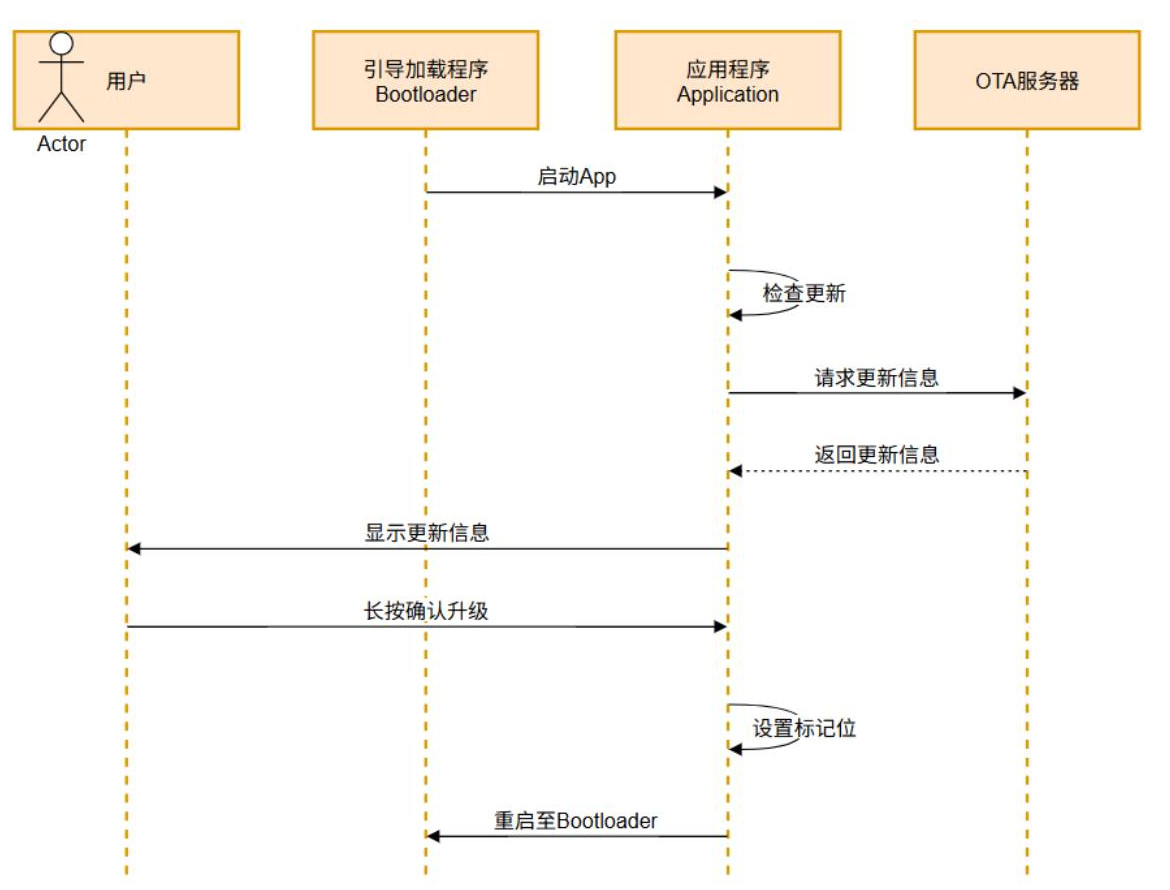

*讲义第67页泳道图主体，关注“长按确认升级 → 设置标记位 → 重启至Bootloader”。*

配套 `store_app.h` 的实际宏名：

```c
#define PARAM_ADDR_IN_FLASH \
        (0x08000000 + BOOTLOADER_SIZE)     /* 0x08008000 */
#define APP_ADDR_IN_FLASH \
        (0x08000000 + BOOTLOADER_SIZE + PARAMETER_SIZE)
#define BACKUP_ADDR_IN_FLASH \
        (0x08000000 + FLASH_SIZE - BACKUP_SIZE)
#define NEED_UPDATE_VERSION_FLAG 0xABCD
```

08的地址表含义延续不变；调用代码时要用以上真实带 `_IN_FLASH` 的宏名。参数结构包含magic、updateFlag、softwareVersion[16]和校验相关存储：

```text
默认升级标志：0xFFFF
请求升级标志：0xABCD
magic：0x5A5A
Param起点：0x08008000，所在分区16 KiB
```

配套写标志函数：

```c
bool SetUpdateVerFlag() {
  uint16_t flag = NEED_UPDATE_VERSION_FLAG;
  if (flag == g_sysParamCurrent.updateFlag) {
    return true;
  }

  // 将升级标记设置到当前结构体里
  SysParam_t sysParam = g_sysParamCurrent;
  sysParam.updateFlag = flag;

  // 将新的结构体写入到Flash的Param区
  if (!WriteSysParam(&sysParam)) {
    return false;
  }

  g_sysParamCurrent = sysParam;
  return true;
}
```

它先复制当前参数结构，在副本上改flag，通过WriteSysParam写入；成功后才更新RAM中的当前参数。WriteSysParam经校验写入层调用FlashErase、FlashWrite，并返回bool。该返回值必须被升级入口使用。

补充改进片段：

```c
/* 放在升级入口完成版本检查之后 */
if (!SetUpdateVerFlag()) {
    printf("升级标志写入失败，保留当前App\r\n");
    return;
}
iap_reset_to_boot();
```

本片段能避免“已知写失败仍立即复位”；如果驱动未做读回验证、或写完后遇到掉电，它并不能自动解决所有持久化问题。

参数写入是擦除后重写，不是给RAM变量赋一个0xABCD那么简单。这里还没有双副本、掉电事务或回滚机制。首次初始化、版本宏同步、擦写失败处理都可能影响参数有效性，应沿 `InitSysParam → WriteSysParam → FlashErase/FlashWrite` 检查。


## 23. 系统复位到Bootloader：哪些信息留下，哪些丢失

配套主控复位函数：

```c
void iap_reset_to_boot(void) {
  // 关闭所有中断
  __disable_irq();
  // 系统复位函数
  NVIC_SystemReset();
}
```

先关中断，再调用 `NVIC_SystemReset()`。这是GD32系统复位，不是ESP的AT+RST，也不是直接从App函数里跳到新App入口。

```text
App长按入口
  → Param写入0xABCD
  → NVIC_SystemReset
  → 主控从复位启动路径进入Bootloader
  → Bootloader初始化参数
  → CheckNeedUpdate检查Flash中的标志
  → 进入无线下载流程
```

| 信息 | App复位后能否靠现有机制保留 |
|---|---|
| 已成功写入Param的updateFlag | 可以，Bootloader再读 |
| 参数区中的当前版本 | 可以，由参数初始化规则处理 |
| App的g_otaVerNo/g_otaBinSize | 普通RAM变量，不应依赖跨复位保留 |
| App的g_otaTaskId | 普通RAM静态变量，不构成持久化 |
| g_targetMD5指针 | 不能作为Bootloader可靠输入 |
| ESP自身网络状态 | ESP是另一芯片，是否重置取决于EN/初始化；不能假设主控复位等于它已重置 |

配套Bootloader会按自己的状态流程联网和查询，不依靠App解析树的地址继续下载。后续如果要把“用户确认的精确目标版本/任务”固定下来，需要设计完整的持久化信息和有效期校验；本课此阶段只传递升级请求标志。

调试提示：App主程序还保留了USART0收到U/u时调用复位函数的入口，**它没有先SetUpdateVerFlag**。串口发U只是复位，不等价于本篇的“长按确认升级”链路。观察Bootloader未进入升级时，要确认触发的是哪一个入口。

Bootloader里何时清标志、下载失败是否回App、覆盖完何时上报结果，放在10继续。不能在App刚复位时提前报告step=201。


## 24. 按阶段复现实验：记录证据与失败路径

本次未运行硬件；以下是依据课程和源码整理的复现步骤及预期：

| 阶段 | 操作/输入 | 观察点 |
|---|---|---|
| 模块检查 | 上电或复位GD32 | RST等ready，ATE0/CWMODE得OK，进入联网 |
| 已连AP | 查询CWJAP? | 收到AP信息后跳过主动连接 |
| 未连AP | 断开后查询，再连接正确热点 | 查询超时→连接→GOT IP→OTA请求 |
| 口令错误 | 独立测试环境换错误口令 | 连接重试、向上FAIL，不能显示“已联网” |
| check有效任务 | 自己的专用任务与Token | 有效JSON、真实版本和大小进入OLED |
| 无效Token/过期任务 | 测试专用身份 | 记录真实业务code，不能误判为升级成功 |
| 短/分段响应 | 本地解析输入或接收回放 | 未完整数据不发布，短字符串不越界 |
| 同版本/无版本 | 当前版本相同或size=0 | 不提示，不触发升级 |
| 有新版本 | 长按1 | 再检查→写flag→复位 |
| 写flag失败 | 独立调试桩返回false | 改进入口不复位，保留App |
| 再次启动 | 查看Bootloader日志/参数 | 读到0xABCD才进入升级分支 |

解析器的本地输入还应覆盖：缺target、size为负数/小数、包大于208 KiB、版本过长、MD5长度不对、type为差分包、JSON截断、末尾多余AT文本。原始课堂函数可能在这些情况下异常，测试改进版时要确认所有错误路径都不会更新半份数据。

日志建议记录：

```text
本轮：主状态/子状态
命令类别：RST、E0、MODE、QUERY_AP、JOIN_AP、CHECK_OTA
结果：WAIT / OK / TIMEOUT / BUSINESS_ERROR / PARSE_ERROR
耗时、累计失败次数
目标版本、文件大小、任务ID（按环境决定是否脱敏）
参数写入结果、复位前最后状态
```

不要直接打印完整CWJAP命令和Authorization。原驱动有整串printf，复现实验可以用它观察格式，但公开日志和截图应脱敏。错误定位依次看串口、联网、HTTP、业务code、字段、显示、Flash参数，避免一个失败同时修改所有层。


## 25. 常见问题、知识自查与本篇交付边界

| 问题 | 核对方向 |
|---|---|
| 每2 ms都发同一命令 | AtCmdHandle等待状态是否保持，是否有第二个调用方干扰 |
| 只有OK没有ready仍卡住 | RST判据本来就是ready |
| 失败次数看起来没到三次就退出 | 本函数retryCount跨命令/再次进入累计 |
| 已显示CONNECTED却HTTP忙 | IP就绪、前一AT命令终态、响应是否丢段 |
| 已有AP仍重新连接 | +CWJAP消息格式/分段、查询超时、接收是否可靠 |
| AT显示JSON却OLED无提示 | 是否调用解析，字段是否有效，是否同版本或size=0 |
| JSON解析失败仍打印DONE | HandleOTA忽略返回值，原码已知行为 |
| 加Delete后MD5异常 | 还在借用valuestring，需先复制到自有数组 |
| 按4后版本忽然变v2.3 | 配套包保留的假数据测试覆盖了真实结果 |
| 恢复Wi-Fi任务又立即停止 | 主状态仍为DONE/ERROR，恢复调度不等于复位状态机 |
| 长按后只重启、不升级 | flag写入是否成功，参数有效性，Bootloader读的地址/规则 |
| 发U与长按行为不同 | U入口未写升级标志 |
| 更新后check还用旧版本 | URL把version写死，需接真实当前版本 |

| 自查题 | 要点 |
|---|---|
| 主/子状态/通信结果分别是什么？ | 业务阶段、阶段内命令、WAIT/OK/FAIL |
| 为什么不能只用else判失败？ | WAIT会被误判 |
| RETRY第3次失败后发生什么？ | 子状态回退、计数清零、向上FAIL |
| 本码每次成功都清retry吗？ | 没有，要认识跨命令累计 |
| WIFI CONNECTED与GOT IP区别？ | 关联AP与取得IP |
| +HTTPCLIENT:能证明任务可升级吗？ | 还需完整JSON、code、字段和策略验证 |
| cJSON_Delete前要做什么？ | 把仍需使用的值复制到自己拥有的存储 |
| App长按后的跨复位凭据是什么？ | Flash参数区升级标志 |
| 重启是否等于升级完成？ | 只是把流程交给Bootloader |
| 本篇还缺哪一半？ | 下载、校验、替换、启动和上报结果 |

**来源记录：** 37、38、40完整自动字幕；39、41按配套源码与讲义核对；讲义67、69、72页原图；App工程中的Wi-Fi、USART、任务、OLED/按键、参数和IAP实现，以及Bootloader对CheckNeedUpdate的使用。字幕SHA-256、源码指纹、图片和核对边界保存在Notebook元数据。

**官方参考：** [OneNET检测升级任务](https://open.iot.10086.cn/doc/v5/fuse/detail/1447)、[ESP32-C3 Wi-Fi AT命令](https://docs.espressif.com/projects/esp-at/zh_CN/latest/esp32c3/AT_Command_Set/Wi-Fi_AT_Commands.html)、[cJSON 1.7.7说明](https://github.com/DaveGamble/cJSON/blob/v1.7.7/README.md)。cJSON版本与配套组件配置对应；在线ESP-AT文档可能更新，复现以自己的AT+GMR和对应固件指南为准。

本篇完成App侧的联网查询、信息展示和升级确认链路说明，保留原码并说明验证、缓冲和持久化边界。**10篇将从Bootloader接过0xABCD标志继续，完成分片下载到Backup、完整性校验、替换App及异常结果处理。**
